# 1 · First meta-analysis: the BCG vaccine data

This notebook walks the whole pipeline on metafor's classic **BCG vaccine
trials** (13 studies):

> 2×2 counts → effect sizes → random-effects pooling → heterogeneity →
> prediction interval → forest plot → summary tables

Every number matches R: `metafor::dat.bcg` + `escalc(measure="RR")` +
`rma(yi, vi)`.

> **中文**　这个 notebook 用 metafor 里的经典 **BCG 疫苗试验**（13 项研究）走一遍完整流程：
> 2×2 计数 → 效应量 → 随机效应合并 → 异质性 → 预测区间 → 森林图 → 结果表。
> 所有数字都能和 R 对上：`metafor::dat.bcg` + `escalc(measure="RR")` + `rma(yi, vi)`。

In [1]:
import math

import numpy as np

import pimeta as ma

## Data: the raw 2×2 counts of 13 trials

The counts go in as `tpos/tneg/cpos/cneg` and `escalc()` does the conversion —
computing an odds ratio by hand is an easy way to get it wrong.

> **中文**　直接给出 `tpos/tneg/cpos/cneg`，让 `escalc()` 去做效应量换算 —— 手工算比值比很容易出错。

In [2]:
study = ["Aronson 1948", "Ferguson & Simes 1949", "Rosenthal et al 1960",
         "Hart & Sutherland 1977", "Frimodt-Moller et al 1973",
         "Stein & Aronson 1953", "Vandiviere et al 1973", "TPT Madras 1980",
         "Coetzee & Berjak 1968", "Rosenthal et al 1961", "Comstock et al 1974",
         "Comstock & Webster 1969", "Comstock et al 1976"]
year = [1948, 1949, 1960, 1977, 1973, 1953, 1973, 1980, 1968, 1961, 1974, 1969, 1976]
tpos = [4, 6, 3, 62, 33, 180, 8, 505, 29, 17, 186, 5, 27]
tneg = [119, 300, 228, 13536, 5036, 1361, 2537, 87886, 7470, 1699, 50448, 2493, 16886]
cpos = [11, 29, 11, 248, 47, 372, 10, 499, 45, 65, 141, 3, 29]
cneg = [128, 274, 209, 12619, 5761, 1079, 619, 87892, 7232, 1600, 27197, 2338, 17825]
print(f"{len(study)} 项试验，共 {sum(tpos) + sum(tneg) + sum(cpos) + sum(cneg):,} 名受试者")

13 项试验，共 357,347 名受试者


## Effect sizes

For **ratio measures** `escalc()` returns values on the **log scale**: `yi` is
log RR, so reporting the RR itself needs `exp()`.

> **中文**　`escalc()` 对**比值类**指标返回的是**对数尺度**：`yi` 是 log RR，要报告 RR 本身需要 `exp()`。

In [3]:
es = ma.escalc("RR", ai=tpos, bi=tneg, ci=cpos, di=cneg)

print("前 4 个 log RR :", np.round(es.yi[:4], 4))
print("还原成 RR      :", np.round(np.exp(es.yi[:4]), 4))
print("方差 vi        :", np.round(es.vi[:4], 4))

前 4 个 log RR : [-0.8893 -1.5854 -1.3481 -1.4416]
还原成 RR      : [0.4109 0.2049 0.2597 0.2366]
方差 vi        : [0.3256 0.1946 0.4154 0.02  ]


## Pooling

The defaults are random effects with the REML estimate of τ², matching
`rma(yi, vi, method="REML")`.

> **中文**　默认就是随机效应 + REML 估计 τ²，与 `rma(yi, vi, method="REML")` 一致。

In [4]:
res = ma.rma(es.yi, es.vi, method="REML", slab=study)

print(f"k = {res.k},  tau^2 = {res.tau2:.5f},  I^2 = {res.I2:.2f}%")
print(f"Q = {res.QE:.3f} (df={res.k - res.p}, p={res.QEp:.4f})")
print()
print(f"合并 RR = {math.exp(float(res.b[0])):.4f} "
      f"[{math.exp(float(res.ci_lb[0])):.4f}, {math.exp(float(res.ci_ub[0])):.4f}]")

k = 13,  tau^2 = 0.31324,  I^2 = 92.22%
Q = 152.233 (df=12, p=0.0000)

合并 RR = 0.4894 [0.3441, 0.6962]


## Forest plot

The plotting helpers return a Matplotlib `Axes`, so the figure renders inline;
pass `filename=` to write it to disk instead.

> **中文**　绘图函数返回 Matplotlib 的 `Axes`，在 notebook 里直接内联显示；也可以传 `filename=` 落盘。

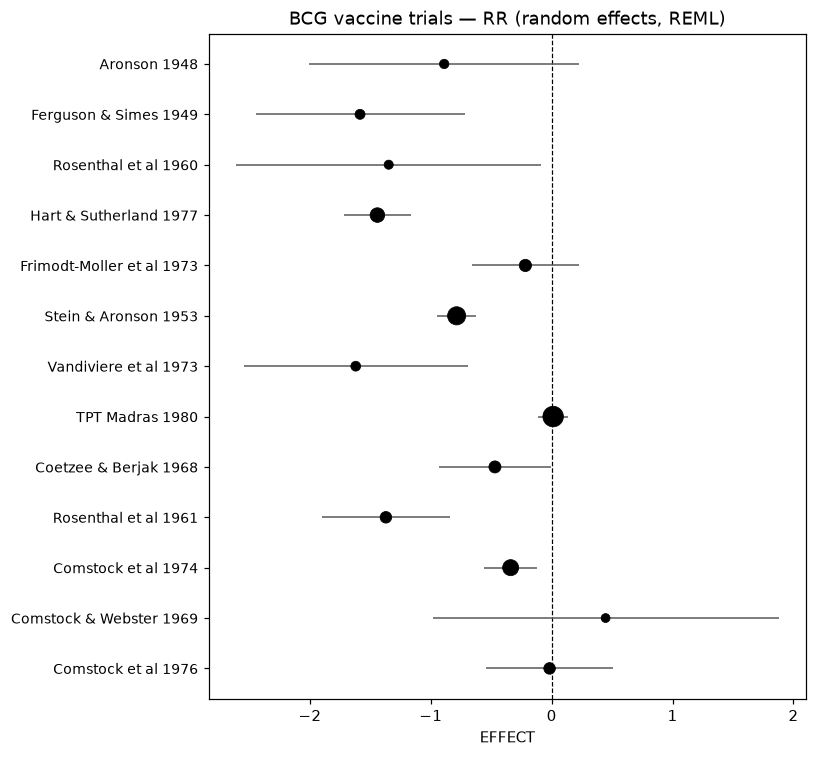

In [5]:
ax = ma.forest(es.yi, es.vi, studlab=study)
_ = ax.set_title("BCG vaccine trials — RR (random effects, REML)")

## Heterogeneity and the prediction interval

`predict()` gives the interval for a **future study**, which is usually much
wider than the confidence interval of the pooled effect — a distinction worth
keeping straight in a report.

> **中文**　`predict()` 给的是**未来研究**的预测区间，通常比合并效应的置信区间宽得多 —— 这在报告里是个重要区别。

In [6]:
pred = ma.predict(res)
ci_tau2 = ma.confint(res)

print(f"合并效应 95% CI : [{pred.ci_lb:.4f}, {pred.ci_ub:.4f}]  (log scale)")
print(f"预测区间        : [{pred.pi_lb:.4f}, {pred.pi_ub:.4f}]  (log scale)")
print(f"tau^2 的 95% CI : [{ci_tau2['ci_lb']:.4f}, {ci_tau2['ci_ub']:.4f}]")

合并效应 95% CI : [-1.0669, -0.3622]  (log scale)
预测区间        : [-1.8667, 0.4376]  (log scale)
tau^2 的 95% CI : [0.1197, 1.1115]


## Summary tables

`tidy()` returns the broom-style one-row-per-coefficient table; `glance()`
returns the model-level statistics.

> **中文**　`tidy()` 给出 broom 风格的一行摘要（每行一个系数），`glance()` 给出模型级指标。

In [7]:
tidy = ma.interop.tidy(res)
glance = ma.interop.glance(res)

# 装了 pandas 就是 DataFrame，没装就是按列的 dict —— 两种都能直接看。
print(tidy.to_string(index=False) if hasattr(tidy, "to_string") else tidy)
print()
row = glance.iloc[0] if hasattr(glance, "iloc") else {k: v[0] for k, v in glance.items()}
print(f"k = {int(row['k'])}, AIC = {float(row['AIC']):.3f}, "
      f"BIC = {float(row['BIC']):.3f}")

   term  estimate  std.error  statistic  p.value  conf.low  conf.high
intrcpt -0.714532   0.179782  -3.974448 0.000071 -1.066898  -0.362167

k = 13, AIC = 28.405, BIC = 29.375


## Takeaway

- `escalc()` computes effect sizes (ratio measures come back on the **log scale**)
- `rma()` pools; `tau2`, `I2` and `Q` live on the result object
- `predict()` is a prediction interval, not a confidence interval
- `tidy()` / `glance()` flatten the result into tables that drop into pandas

Next: [`02-meta-regression.ipynb`](02-meta-regression.ipynb) uses moderators to
explain this heterogeneity.

> **中文**
> - `escalc()` 算效应量（比值类返回**对数尺度**）
> - `rma()` 合并，`tau2` / `I2` / `Q` 都在结果对象上
> - `predict()` 是预测区间，不是置信区间
> - `tidy()` / `glance()` 把结果摊平成表，能直接进 pandas
>
> 下一步：在 [`02-meta-regression.ipynb`](02-meta-regression.ipynb) 里用调节变量解释这份异质性。